# Modeling and Evaluation

## 1. Load Data and Define Features and Target

In [ ]:
import pandas as pd


df = pd.read_csv("../Data/Cleaned/train_FD001_cleaned.csv")

X = df.drop(columns=["RUL", "engine_id"])


y = df["RUL"]


groups = df["engine_id"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Number of engines:", groups.nunique())

display(X.head())

Features shape: (20631, 18)
Target shape: (20631,)
Number of engines: 100


,cycle,setting_1,setting_2,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,1,-0.0007,-0.0004,641.82,1589.70,1400.60,21.61,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190
1,2,0.0019,-0.0003,642.15,1591.82,1403.14,21.61,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236
2,3,-0.0043,0.0003,642.35,1587.99,1404.20,21.61,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442
3,4,0.0007,0.0000,642.35,1582.79,1401.87,21.61,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739
4,5,-0.0019,-0.0002,642.37,1582.85,1406.22,21.61,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044


## 2. Define Models and Preprocessing Pipelines

StandardScaler is applied to Linear Regression and Ridge within their pipelines.
Tree-based models are used without scaling.

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),

    "Random Forest": Pipeline([
        ("model", RandomForestRegressor(
            n_estimators=100,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("model", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        ))
    ])
}

print("Models:", list(models))

Models: ['Linear Regression', 'Ridge', 'Random Forest', 'Gradient Boosting']


## 3. Compare Models Using Grouped Cross-Validation

Five-fold GroupKFold keeps each engine entirely within either training
or validation in each fold. Models are compared using mean validation
MAE, RMSE, and R² across folds.

In [3]:
from sklearn.model_selection import GroupKFold, cross_validate

cv = GroupKFold(n_splits=5)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

results = []

for name, model in models.items():
    print(f"Evaluating: {name}")

    scores = cross_validate(
        model,
        X,
        y,
        groups=groups,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    results.append({
        "Model": name,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R²": scores["test_R2"].mean()
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(results_df.round(3))

Evaluating: Linear Regression
Evaluating: Ridge
Evaluating: Random Forest
Evaluating: Gradient Boosting


,Model,MAE,RMSE,R²
0,Gradient Boosting,26.481,37.316,0.706
1,Random Forest,26.768,38.075,0.694
2,Ridge,31.159,40.556,0.652
3,Linear Regression,31.159,40.556,0.652


In [4]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    "Random Forest": {
        "model__n_estimators": [100],
        "model__max_depth": [10, None],
        "model__min_samples_leaf": [2, 5]
    },

    "Gradient Boosting": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3]
    }
}

searches = []

for name, param_grid in param_grids.items():
    print(f"Tuning: {name}")

    search = GridSearchCV(
        estimator=models[name],
        param_grid=param_grid,
        scoring=scoring,
        refit="RMSE",
        cv=cv,
        n_jobs=-1,
        error_score="raise"
    )

    search.fit(X, y, groups=groups)
    searches.append((name, search))

    print("Best parameters:", search.best_params_)
    print("Best CV RMSE:", round(-search.best_score_, 3))

Tuning: Random Forest
Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 100}
Best CV RMSE: 37.617
Tuning: Gradient Boosting
Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 200}
Best CV RMSE: 37.236


### Tuning Results

Hyperparameter tuning slightly improved both models.
Gradient Boosting achieved the lowest mean cross-validation RMSE
of 37.236 cycles, compared with 37.617 for Random Forest.
The tuned Gradient Boosting model is the leading candidate,
pending evaluation on the official test set.

In [ ]:
## 5. Prepare the Official Test Set

In [ ]:

columns = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)


test_df = pd.read_csv(
    "../Data/Original/test_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

y_test = pd.read_csv(
    "../Data/Original/RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=["RUL"]
)["RUL"]


test_last = (
    test_df.sort_values(["engine_id", "cycle"])
    .groupby("engine_id")
    .tail(1)
    .sort_values("engine_id")
    .reset_index(drop=True)
)


X_test = test_last[X.columns].copy()

assert len(X_test) == len(y_test)

print("Test features:", X_test.shape)
print("Test target:", y_test.shape)

display(test_last[["engine_id", "cycle"]].head())
display(y_test.head())

Test features: (100, 18)
Test target: (100,)


,engine_id,cycle
0,1,31
1,2,49
2,3,126
3,4,106
4,5,98


0    112
1     98
2     69
3     82
4     91
Name: RUL, dtype: int64

In [ ]:
from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)
final_models = {
    name: clone(model)
    for name, model in models.items()
}

for name, search in searches:
    final_models[name] = clone(search.best_estimator_)

test_results = []
test_predictions = {}

for name, model in final_models.items():

    model.fit(X, y)

  
    predictions = model.predict(X_test)
    test_predictions[name] = predictions

    test_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": root_mean_squared_error(y_test, predictions),
        "R²": r2_score(y_test, predictions)
    })

test_results_df = (
    pd.DataFrame(test_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(test_results_df.round(3))

,Model,MAE,RMSE,R²
0,Gradient Boosting,18.831,25.226,0.632
1,Random Forest,19.139,25.606,0.620
2,Ridge,25.975,31.250,0.434
3,Linear Regression,25.975,31.250,0.434


In [7]:
from pathlib import Path
import joblib
import json

models_dir = Path("../Models")
models_dir.mkdir(parents=True, exist_ok=True)

for name, model in final_models.items():
    filename = name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(model, models_dir / filename)


with open(models_dir / "feature_columns.json", "w") as file:
    json.dump(X.columns.tolist(), file, indent=2)


test_results_df.to_csv(
    models_dir / "test_results.csv",
    index=False
)

print("Saved all four models, feature names, and test results.")

Saved all four models, feature names, and test results.


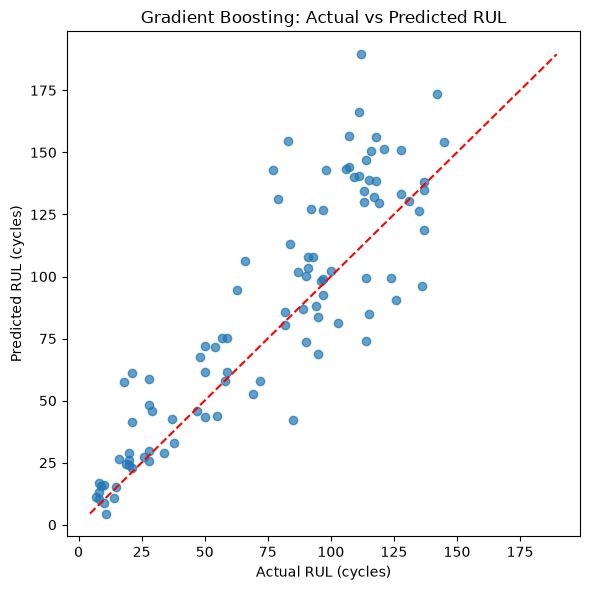

: 

In [ ]:
import matplotlib.pyplot as plt

pred = test_predictions["Gradient Boosting"]

plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.7)

lower = min(y_test.min(), pred.min())
upper = max(y_test.max(), pred.max())

plt.plot([lower, upper], [lower, upper], "r--")

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("Gradient Boosting: Actual vs Predicted RUL")
plt.tight_layout()
plt.show()

### Actual vs Predicted RUL

Predictions generally follow the ideal diagonal, but noticeable errors remain.
The plot suggests greater prediction spread at medium and high actual RUL.
Some engines with low actual RUL receive overestimated predictions,
which could delay maintenance. The model remains a prototype.

In [ ]:

import matplotlib.pyplot as plt

pred = test_predictions["Gradient Boosting"]

plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.7)

lower = min(y_test.min(), pred.min())
upper = max(y_test.max(), pred.max())

plt.plot([lower, upper], [lower, upper], "r--")

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("Gradient Boosting: Actual vs Predicted RUL")
plt.tight_layout()
plt.show()